# Khám phá dữ liệu

**Vai trò:** ghi lại EDA và quyết định tiền xử lý cho bộ dữ liệu bệnh tim.

## Các bước cần thực hiện
1. Ghi nguồn, phiên bản, ngày tải, giấy phép và mô tả mỗi dòng dữ liệu.
2. Kiểm tra kích thước, kiểu dữ liệu, missing values, dòng trùng và miền giá trị.
3. Khảo sát phân phối biến số/biến phân loại và quan hệ giữa các thuộc tính.
4. Xác định cột đầu vào phân cụm và giữ nhãn chẩn đoán riêng nếu có.
5. Ghi rõ lựa chọn làm sạch, mã hóa, scaling và metric khoảng cách.

Notebook hiện chỉ có ghi chú; chưa nạp dữ liệu và chưa có ô mã. Chuyển logic dùng lại vào `src/` khi bắt đầu implementation.

## 1.Nguồn dữ liệu

- **Tệp:** `data/raw/heart.csv` (dữ liệu gốc, không chỉnh sửa; bị `.gitignore` loại khỏi Git).
- **Nguồn / phiên bản / ngày tải / giấy phép:** Kaggle/ahmedgmy/heart-disease,Phiên bản ver2,4/9/2026,công khai
- **Mỗi dòng:** hồ sơ của một bệnh nhân với 13 thuộc tính + `target` (chẩn đoán bệnh tim: 1 có, 0 không).

In [1]:
%pip install matplotlib
%pip install seaborn
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import (
    load_heart_data, drop_duplicate_rows, split_features_target, data_quality_report,
    NUMERIC_COLS, CATEGORICAL_COLS, BINARY_COLS, TARGET_COL,
)
from src.preprocessing import preprocess_features

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

## 2. Kích thước, kiểu dữ liệu, thiếu, trùng, giá trị bất thường

In [3]:
df_raw = load_heart_data(ROOT / "data" / "raw" / "heart.csv")
print(df_raw.shape)
df_raw.dtypes

(1025, 14)


age           int64
trestbps      int64
chol          int64
thalach       int64
oldpeak     float64
cp            int64
restecg       int64
slope         int64
ca            int64
thal          int64
sex           int64
fbs           int64
exang         int64
target        int64
dtype: object

In [4]:
report = data_quality_report(df_raw)
report

{'n_rows': 1025,
 'n_cols': 14,
 'n_missing': 0,
 'n_duplicates': 723,
 'unexpected_values': {'ca': {4: 18}}}

**Ghi chú quyết định**
- Dữ liệu không có giá trị thiếu *(xác nhận qua `n_missing` ở trên)*.
- `df.drop_duplicates()` được áp dụng **trước khi phân cụm**.
- `ca` có mã 4 là giá trị bất thường của bộ dữ liệu; mã này được **giữ nguyên** và đưa vào One-Hot như một nhóm riêng (xem số dòng ở `unexpected_values`).

In [5]:
df = drop_duplicate_rows(df_raw)
print(f"Trước: {len(df_raw)} dòng | Sau drop_duplicates: {len(df)} dòng | Đã bỏ: {len(df_raw) - len(df)}")
df.describe().T

Trước: 1025 dòng | Sau drop_duplicates: 302 dòng | Đã bỏ: 723


,count,mean,std,min,25%,50%,75%,max
age,302.0,54.420530,9.047970,29.0,48.00,55.5,61.00,77.0
trestbps,302.0,131.602649,17.563394,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.500000,51.753489,126.0,211.00,240.5,274.75,564.0
thalach,302.0,149.569536,22.903527,71.0,133.25,152.5,166.00,202.0
oldpeak,302.0,1.043046,1.161452,0.0,0.00,0.8,1.60,6.2
cp,302.0,0.963576,1.032044,0.0,0.00,1.0,2.00,3.0
restecg,302.0,0.526490,0.526027,0.0,0.00,1.0,1.00,2.0
slope,302.0,1.397351,0.616274,0.0,1.00,1.0,2.00,2.0
ca,302.0,0.718543,1.006748,0.0,0.00,0.0,1.00,4.0
thal,302.0,2.314570,0.613026,0.0,2.00,2.0,3.00,3.0


## 3. Phân phối biến

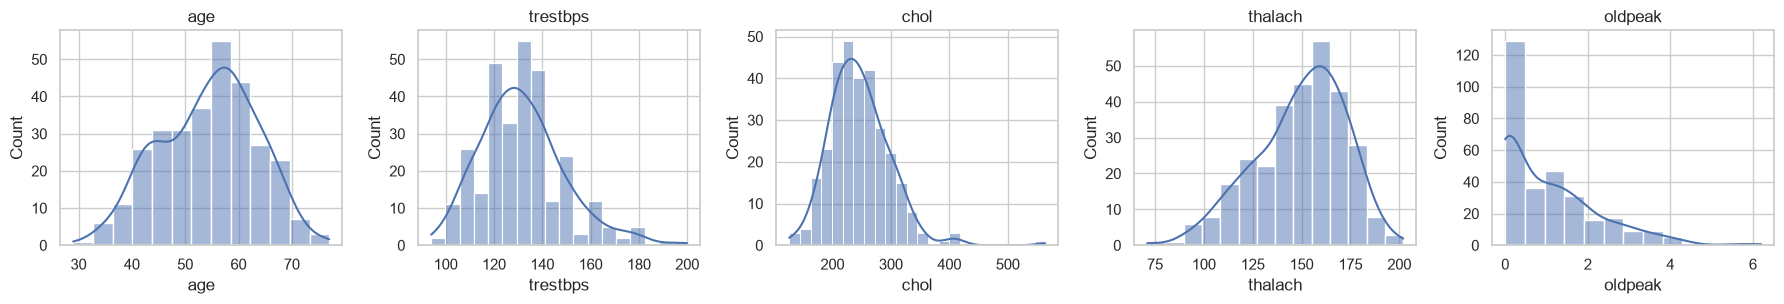

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

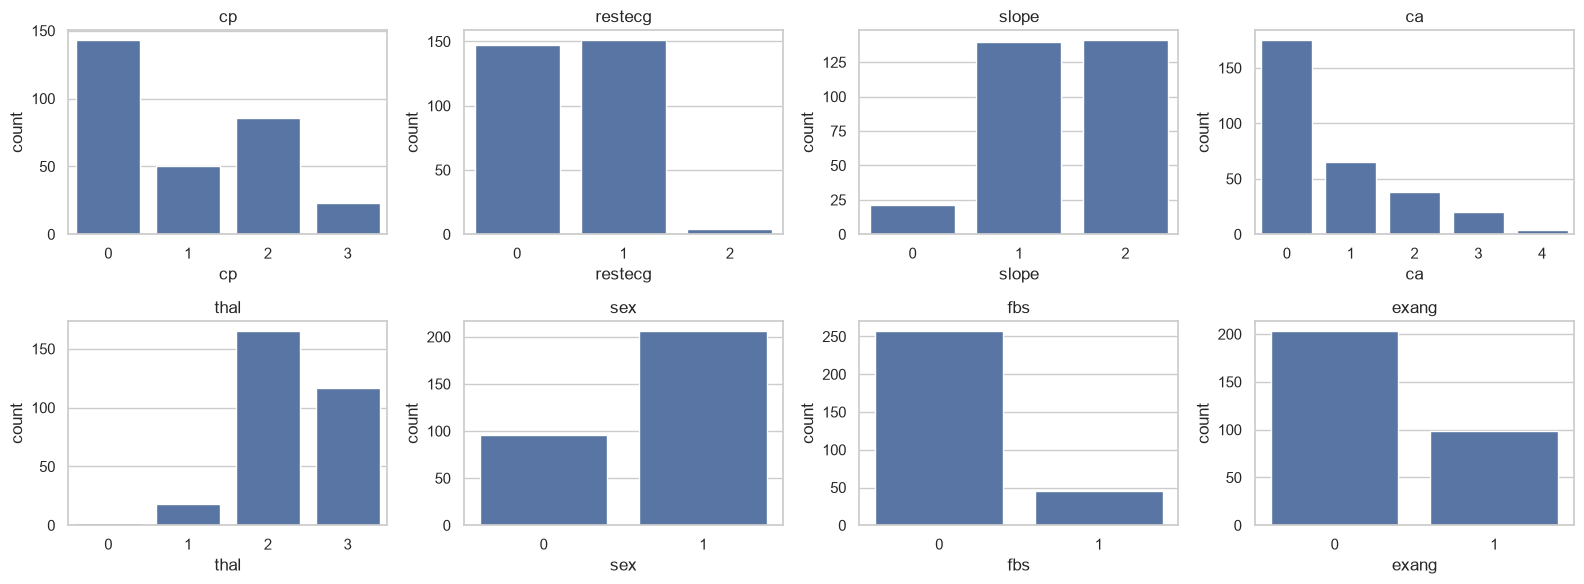

In [ ]:
cat_cols = CATEGORICAL_COLS + BINARY_COLS
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [8]:
df[TARGET_COL].value_counts().rename("n").to_frame().assign(tỉ_lệ=lambda t: (t["n"] / t["n"].sum()).round(3))

,n,tỉ_lệ
target,,
1,164,0.543
0,138,0.457


## 4. Quan hệ giữa các biến số

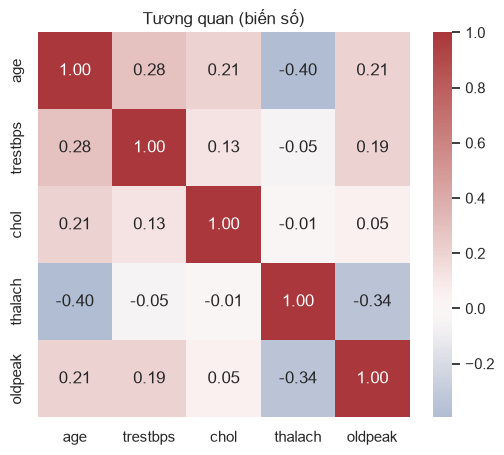

In [17]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[NUMERIC_COLS].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Tương quan (biến số)")
plt.show()

## 5. Quyết định tiền xử lý

| Nhóm | Cột | Xử lý |
|---|---|---|
| Biến số | age, trestbps, chol, thalach, oldpeak | `StandardScaler` |
| Biến phân loại | cp, restecg, slope, ca, thal | `OneHotEncoder` |
| Biến nhị phân | sex, fbs, exang | giữ nguyên |
| Nhãn | target | tách riêng, **không** đưa vào phân cụm; chỉ kiểm tra sau phân cụm |

- **Metric chính:** Manhattan trên ma trận đã tiền xử lý.
- **Đối chứng:** Gower tính trên 13 cột gốc (số: hiệu / khoảng giá trị; phân loại & nhị phân: khớp/không khớp) → `KMedoids(metric='precomputed')`.
- **Mô hình:** `sklearn_extra.cluster.KMedoids(method='pam', init='k-medoids++', random_state=42)`, chọn k trong 2–8 bằng silhouette.

In [14]:
X, y = split_features_target(df)
X_mat, feature_names, pre = preprocess_features(X)
print("Ma trận đặc trưng:", X_mat.shape)
print(feature_names)

Ma trận đặc trưng: (302, 27)
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'cp_0', 'cp_1', 'cp_2', 'cp_3', 'restecg_0', 'restecg_1', 'restecg_2', 'slope_0', 'slope_1', 'slope_2', 'ca_0', 'ca_1', 'ca_2', 'ca_3', 'ca_4', 'thal_0', 'thal_1', 'thal_2', 'thal_3', 'sex', 'fbs', 'exang']
